In [ ]:
# ============================================================
# 1. IMPORTS
# ============================================================
# This cell imports all Python libraries needed for:
# - file handling
# - image preprocessing
# - deep learning with PyTorch
# - evaluation metrics
# - plotting results

import os
import zipfile
import random
import shutil
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Imports completed successfully.")

Imports completed successfully.


In [ ]:
# ============================================================
# 2. REPRODUCIBILITY SETTINGS
# ============================================================
# Neural network training contains several random operations:
#
# - random initialization of model weights
# - random shuffling of training images
# - random horizontal flipping
# - random rotation
# - random brightness/contrast augmentation
#
# To make our experiment reproducible, we fix the random seed.
# This helps ensure that running the notebook again gives
# approximately the same training behavior and results.

import random
import numpy as np
import torch


SEED = 42


def set_seed(seed=SEED):
    """
    Set random seeds for Python, NumPy and PyTorch.
    """

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Make CUDA operations deterministic where possible
    torch.backends.cudnn.deterministic = True

    # Disable automatic algorithm benchmarking because it can
    # select slightly different algorithms between runs
    torch.backends.cudnn.benchmark = False


set_seed()

print("Random seed fixed at:", SEED)

Random seed fixed at: 42


In [ ]:
# ============================================================
# 3. GOOGLE DRIVE SETUP
# ============================================================
# We mount Google Drive because our:
# - dataset ZIP files
# - trained model checkpoints
# - external test files
# are stored permanently in Google Drive.
#
# Files stored inside /content can disappear when Colab restarts,
# but files stored in Google Drive remain safe.

from google.colab import drive

drive.mount("/content/drive")

# Main project folder in Google Drive
PROJECT_DIR = "/content/drive/MyDrive/MyDrive onion_project "

# Check whether the folder exists
print("Project folder exists:", os.path.exists(PROJECT_DIR))

# Display the files inside the project folder
print("\nProject files:")
print(os.listdir(PROJECT_DIR))

Mounted at /content/drive
Project folder exists: True

Project files:
['onion_final.zip', 'improved_cnn_best.pth', 'mobilenetv3_small_best.pth', 'external_collection.zip', 'mobilenetv3_external_finetuned.pth', 'new_external_test.zip', 'mobilenetv3_reproducible_best.pth', 'mobilenetv3_reproducible_external_finetuned.pth', 'Copy of final_onion_project.ipynb']


In [ ]:
# ============================================================
# 4. DEVICE SETUP
# ============================================================
# Deep learning models train and run much faster on a GPU.
#
# If a GPU is available in Google Colab, PyTorch will use CUDA.
# Otherwise, the code automatically falls back to the CPU.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Display the GPU name if one is available
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Using device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# 5. EXTRACT ORIGINAL DATASET
# ============================================================
# The original onion dataset is stored as a ZIP file in Google Drive.
#
# We extract it into /content because reading images from /content
# is faster than reading them directly from Google Drive.
#
# Important:
# /content is temporary and will be cleared if Colab restarts.
# The ZIP file in Google Drive remains safe.

ONION_ZIP = os.path.join(PROJECT_DIR, "onion_final.zip")

EXTRACT_DIR = "/content/onion_data"

# Extract only if the dataset has not already been extracted
if not os.path.exists(os.path.join(EXTRACT_DIR, "onion_final")):

    with zipfile.ZipFile(ONION_ZIP, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Dataset extracted successfully.")

else:
    print("Dataset is already extracted.")

# Main dataset path
BASE_PATH = os.path.join(EXTRACT_DIR, "onion_final")

print("Dataset path:", BASE_PATH)
print("Dataset exists:", os.path.exists(BASE_PATH))

Dataset extracted successfully.
Dataset path: /content/onion_data/onion_final
Dataset exists: True


In [ ]:
# ============================================================
# 6. VERIFY DATASET
# ============================================================
# Our final curated dataset contains three splits:
#
# Train      -> used to train the models
# Validation -> used during model development/model selection
# Test       -> kept untouched for final evaluation
#
# Each split contains:
# healthy
# unhealthy

for split in ["train", "validation", "test"]:

    print(f"\n{split.upper()}")

    for label in ["healthy", "unhealthy"]:

        folder = os.path.join(BASE_PATH, split, label)

        # Count only image files
        count = len([
            filename
            for filename in os.listdir(folder)
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ])

        print(f"{label}: {count}")


TRAIN
healthy: 700
unhealthy: 700

VALIDATION
healthy: 150
unhealthy: 150

TEST
healthy: 150
unhealthy: 150


In [ ]:
# ============================================================
# 7. IMAGE PREPROCESSING AND AUGMENTATION
# ============================================================
# All images are resized to 224 x 224 because MobileNetV3-Small
# and our CNN models use this input size.
#
# Training images use light augmentation to help the model
# generalize better and reduce overfitting.
#
# Validation and test images are NOT augmented.
# They only use resizing and normalization.

IMG_SIZE = 224

# Training transform
# These augmentations slightly change the image while keeping
# the onion's health label unchanged.
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Randomly flip some training images horizontally
    transforms.RandomHorizontalFlip(p=0.5),

    # Apply a small rotation
    transforms.RandomRotation(5),

    # Slightly vary brightness and contrast
    transforms.ColorJitter(
        brightness=0.05,
        contrast=0.05
    ),

    # Convert image to PyTorch tensor
    transforms.ToTensor(),

    # Normalize using ImageNet mean and standard deviation.
    # This is important because MobileNetV3 was pretrained on ImageNet.
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation/test transform
# No random augmentation is used here because evaluation
# should be consistent and repeatable.
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training and evaluation transforms created successfully.")

Training and evaluation transforms created successfully.


In [ ]:
# ============================================================
# 8. CREATE DATASETS AND REPRODUCIBLE DATALOADERS
# ============================================================
# ImageFolder reads images from the class folders and assigns:
#
# healthy   -> 0
# unhealthy -> 1
#
# We also use a seeded PyTorch generator so that training
# images are shuffled in the same deterministic order when
# the experiment is repeated.

train_dir = os.path.join(BASE_PATH, "train")
val_dir = os.path.join(BASE_PATH, "validation")
test_dir = os.path.join(BASE_PATH, "test")


train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)


BATCH_SIZE = 32


def create_dataloaders(seed=SEED):
    """
    Create reproducible DataLoaders.

    A fresh seeded generator ensures that the training
    dataset is shuffled consistently between experiments.
    """

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = create_dataloaders()


print("Class mapping:", train_dataset.class_to_idx)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Class mapping: {'healthy': 0, 'unhealthy': 1}
Train images: 1400
Validation images: 300
Test images: 300


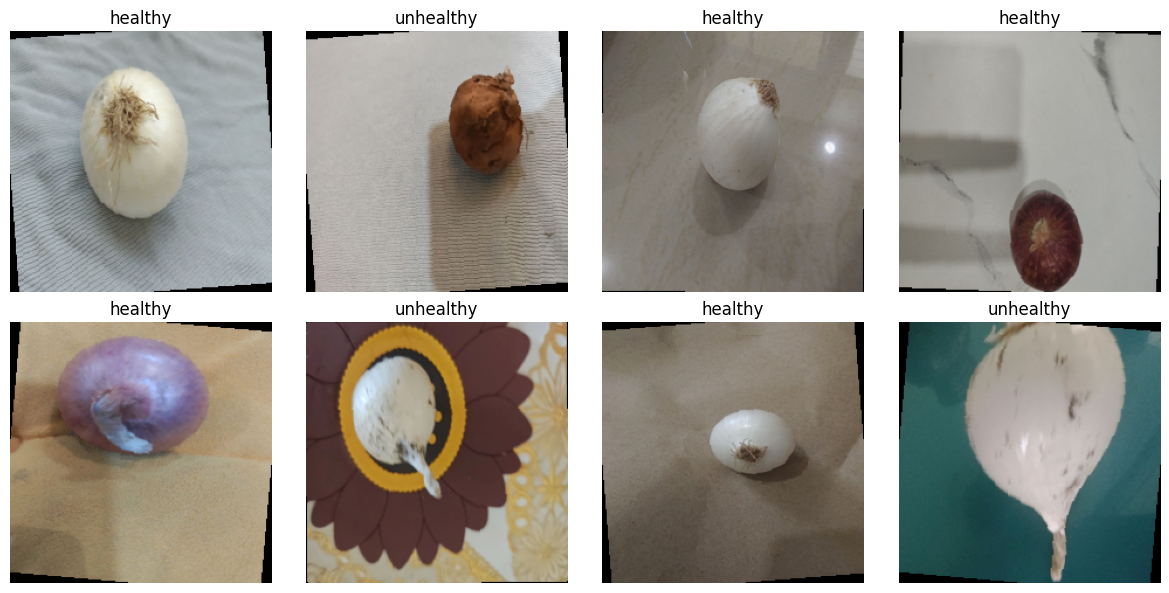

In [ ]:
# ============================================================
# 9. VISUALIZE SAMPLE TRAINING IMAGES
# ============================================================
# This cell displays a few images from the training DataLoader.
#
# Because the training transform includes random augmentation,
# the displayed images may appear slightly flipped, rotated,
# or adjusted in brightness/contrast.
#
# We reverse the ImageNet normalization only for visualization.

# Get one batch of training images
images, labels = next(iter(train_loader))

# ImageNet normalization values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

plt.figure(figsize=(12, 6))

# Display the first 8 images
for i in range(8):

    plt.subplot(2, 4, i + 1)

    # Convert tensor from:
    # [channels, height, width]
    # to:
    # [height, width, channels]
    img = images[i].permute(1, 2, 0).numpy()

    # Reverse normalization for display
    img = std * img + mean
    img = np.clip(img, 0, 1)

    plt.imshow(img)

    # Get class name from numerical label
    class_name = train_dataset.classes[labels[i].item()]

    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 11. SIMPLE CNN BASELINE MODEL
# ============================================================
# SimpleCNN is our baseline deep-learning model.
#
# It contains:
# - 3 convolutional layers
# - ReLU activation
# - max pooling
# - fully connected classification layers
# - dropout
#
# Before creating the model, we reset the random seed and
# recreate the training DataLoader. This makes the model
# initialization and training-data order reproducible.

class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 28 * 28,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(128, 1)
        )


    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


# ------------------------------------------------------------
# RESET RANDOM STATE BEFORE SIMPLECNN
# ------------------------------------------------------------
set_seed(SEED)

train_loader, val_loader, test_loader = create_dataloaders(
    seed=SEED
)


# Create the model only AFTER resetting the seed
simple_cnn = SimpleCNN().to(device)

print(simple_cnn)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================================
# 12. SIMPLE CNN TRAINING SETUP
# ============================================================

simple_criterion = nn.BCEWithLogitsLoss()

simple_optimizer = optim.Adam(
    simple_cnn.parameters(),
    lr=0.001
)

print("Loss function: BCEWithLogitsLoss")
print("Optimizer: Adam")

Loss function: BCEWithLogitsLoss
Optimizer: Adam


In [ ]:
# ============================================================
# 13. TRAIN SIMPLE CNN
# ============================================================
# We train for 10 epochs and keep the model weights that give
# the lowest validation loss.
#
# This allows us to avoid keeping a worse model from a later
# epoch if overfitting starts.

SIMPLE_EPOCHS = 10

best_simple_val_loss = float("inf")
best_simple_weights = copy.deepcopy(
    simple_cnn.state_dict()
)

simple_train_losses = []
simple_val_losses = []
simple_train_accs = []
simple_val_accs = []


for epoch in range(SIMPLE_EPOCHS):

    # -------------------------
    # TRAINING
    # -------------------------
    simple_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)

        labels = (
            labels.float()
            .unsqueeze(1)
            .to(device)
        )

        simple_optimizer.zero_grad()

        outputs = simple_cnn(images)

        loss = simple_criterion(
            outputs,
            labels
        )

        loss.backward()
        simple_optimizer.step()

        train_loss += (
            loss.item() *
            images.size(0)
        )

        probs = torch.sigmoid(outputs)

        preds = (
            probs >= 0.5
        ).float()

        train_correct += (
            preds == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total


    # -------------------------
    # VALIDATION
    # -------------------------
    simple_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)

            labels = (
                labels.float()
                .unsqueeze(1)
                .to(device)
            )

            outputs = simple_cnn(images)

            loss = simple_criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item() *
                images.size(0)
            )

            probs = torch.sigmoid(outputs)

            preds = (
                probs >= 0.5
            ).float()

            val_correct += (
                preds == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # Save history
    simple_train_losses.append(train_loss)
    simple_val_losses.append(val_loss)

    simple_train_accs.append(train_acc)
    simple_val_accs.append(val_acc)


    # Keep best validation model
    if val_loss < best_simple_val_loss:

        best_simple_val_loss = val_loss

        best_simple_weights = copy.deepcopy(
            simple_cnn.state_dict()
        )


    print(
        f"Epoch {epoch+1}/{SIMPLE_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


# Restore best model
simple_cnn.load_state_dict(
    best_simple_weights
)

print(
    "\nBest validation loss:",
    best_simple_val_loss
)

Epoch 1/10 | Train Loss: 0.7260 | Train Acc: 0.5707 | Val Loss: 0.6617 | Val Acc: 0.5967
Epoch 2/10 | Train Loss: 0.6225 | Train Acc: 0.6214 | Val Loss: 0.5975 | Val Acc: 0.5967
Epoch 3/10 | Train Loss: 0.5863 | Train Acc: 0.6650 | Val Loss: 0.5980 | Val Acc: 0.6067
Epoch 4/10 | Train Loss: 0.5675 | Train Acc: 0.6814 | Val Loss: 0.5033 | Val Acc: 0.7367
Epoch 5/10 | Train Loss: 0.4760 | Train Acc: 0.7486 | Val Loss: 0.4951 | Val Acc: 0.7800
Epoch 6/10 | Train Loss: 0.4291 | Train Acc: 0.7829 | Val Loss: 0.4943 | Val Acc: 0.7600
Epoch 7/10 | Train Loss: 0.4411 | Train Acc: 0.7771 | Val Loss: 0.4736 | Val Acc: 0.7300
Epoch 8/10 | Train Loss: 0.3684 | Train Acc: 0.8186 | Val Loss: 0.4509 | Val Acc: 0.8167
Epoch 9/10 | Train Loss: 0.3337 | Train Acc: 0.8379 | Val Loss: 0.3982 | Val Acc: 0.8200
Epoch 10/10 | Train Loss: 0.3359 | Train Acc: 0.8571 | Val Loss: 0.4013 | Val Acc: 0.8367

Best validation loss: 0.3982084353764852


In [ ]:
# ============================================================
# 14. IMPROVED CNN MODEL
# ============================================================
# ImprovedCNN extends the baseline model by adding:
#
# - Batch Normalization
# - an additional convolutional block
# - Adaptive Average Pooling
# - Dropout
#
# As with SimpleCNN, we reset the random state immediately
# before creating this model.

class ImprovedCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                128, 256,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Dropout(0.3),

            nn.Linear(256, 1)
        )


    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


# ------------------------------------------------------------
# RESET RANDOM STATE BEFORE IMPROVEDCNN
# ------------------------------------------------------------
set_seed(SEED)

train_loader, val_loader, test_loader = create_dataloaders(
    seed=SEED
)


# Create model after resetting randomness
improved_cnn = ImprovedCNN().to(device)

print(improved_cnn)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, aff

In [ ]:
# ============================================================
# 15. IMPROVED CNN TRAINING SETUP
# ============================================================
# BCEWithLogitsLoss is again used for binary classification.
#
# AdamW is used instead of Adam because it supports
# weight decay more cleanly, which helps regularization.
#
# ReduceLROnPlateau reduces the learning rate if validation
# loss stops improving.

improved_criterion = nn.BCEWithLogitsLoss()

improved_optimizer = optim.AdamW(
    improved_cnn.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

improved_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    improved_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Scheduler: ReduceLROnPlateau")

Loss function: BCEWithLogitsLoss
Optimizer: AdamW
Scheduler: ReduceLROnPlateau


In [ ]:
# ============================================================
# 16. TRAIN IMPROVED CNN
# ============================================================
# We allow up to 30 epochs.
#
# Early stopping is used so training stops if validation loss
# does not improve for 5 consecutive epochs.
#
# The model with the lowest validation loss is restored at
# the end.

IMPROVED_MAX_EPOCHS = 30
IMPROVED_PATIENCE = 5

best_improved_val_loss = float("inf")

best_improved_weights = copy.deepcopy(
    improved_cnn.state_dict()
)

epochs_without_improvement = 0

improved_train_losses = []
improved_val_losses = []
improved_train_accs = []
improved_val_accs = []


for epoch in range(IMPROVED_MAX_EPOCHS):

    # ========================================================
    # TRAINING
    # ========================================================
    improved_cnn.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0


    for images, labels in train_loader:

        images = images.to(device)

        labels = (
            labels.float()
            .unsqueeze(1)
            .to(device)
        )

        improved_optimizer.zero_grad()

        outputs = improved_cnn(images)

        loss = improved_criterion(
            outputs,
            labels
        )

        loss.backward()

        improved_optimizer.step()

        train_loss += (
            loss.item() *
            images.size(0)
        )

        probabilities = torch.sigmoid(outputs)

        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)


    train_loss /= train_total

    train_accuracy = (
        train_correct /
        train_total
    )


    # ========================================================
    # VALIDATION
    # ========================================================
    improved_cnn.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)

            labels = (
                labels.float()
                .unsqueeze(1)
                .to(device)
            )

            outputs = improved_cnn(images)

            loss = improved_criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item() *
                images.size(0)
            )

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)


    val_loss /= val_total

    val_accuracy = (
        val_correct /
        val_total
    )


    # Save history
    improved_train_losses.append(train_loss)
    improved_val_losses.append(val_loss)

    improved_train_accs.append(train_accuracy)
    improved_val_accs.append(val_accuracy)


    # Update learning-rate scheduler
    improved_scheduler.step(val_loss)

    current_lr = (
        improved_optimizer
        .param_groups[0]["lr"]
    )


    # ========================================================
    # SAVE BEST MODEL
    # ========================================================
    if val_loss < best_improved_val_loss:

        best_improved_val_loss = val_loss

        best_improved_weights = copy.deepcopy(
            improved_cnn.state_dict()
        )

        epochs_without_improvement = 0

        print("-> New best ImprovedCNN")

    else:

        epochs_without_improvement += 1


    print(
        f"Epoch {epoch+1}/{IMPROVED_MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.6f}"
    )


    # ========================================================
    # EARLY STOPPING
    # ========================================================
    if epochs_without_improvement >= IMPROVED_PATIENCE:

        print("\nEarly stopping triggered.")

        break


# Restore the best validation model
improved_cnn.load_state_dict(
    best_improved_weights
)

print("\nImprovedCNN training finished.")

print(
    "Best validation loss:",
    best_improved_val_loss
)

-> New best ImprovedCNN
Epoch 1/30 | Train Loss: 0.6662 | Train Acc: 0.5971 | Val Loss: 0.7107 | Val Acc: 0.5533 | LR: 0.001000
-> New best ImprovedCNN
Epoch 2/30 | Train Loss: 0.6404 | Train Acc: 0.5950 | Val Loss: 0.6508 | Val Acc: 0.5867 | LR: 0.001000
Epoch 3/30 | Train Loss: 0.6238 | Train Acc: 0.6243 | Val Loss: 0.6565 | Val Acc: 0.6233 | LR: 0.001000
-> New best ImprovedCNN
Epoch 4/30 | Train Loss: 0.5969 | Train Acc: 0.6536 | Val Loss: 0.6394 | Val Acc: 0.6533 | LR: 0.001000
-> New best ImprovedCNN
Epoch 5/30 | Train Loss: 0.6148 | Train Acc: 0.6429 | Val Loss: 0.6178 | Val Acc: 0.6233 | LR: 0.001000
-> New best ImprovedCNN
Epoch 6/30 | Train Loss: 0.6001 | Train Acc: 0.6443 | Val Loss: 0.5860 | Val Acc: 0.6500 | LR: 0.001000
-> New best ImprovedCNN
Epoch 7/30 | Train Loss: 0.5825 | Train Acc: 0.6786 | Val Loss: 0.5657 | Val Acc: 0.6833 | LR: 0.001000
Epoch 8/30 | Train Loss: 0.5795 | Train Acc: 0.6764 | Val Loss: 0.6155 | Val Acc: 0.6500 | LR: 0.001000
Epoch 9/30 | Train Loss:

In [ ]:
# ============================================================
# 16. MOBILENETV3-SMALL TRANSFER LEARNING MODEL
# ============================================================
# MobileNetV3-Small is a pretrained convolutional neural network.
#
# Instead of learning all visual features from scratch, it starts
# with features learned from the ImageNet dataset.
#
# Transfer learning is useful here because our onion dataset is
# relatively small compared with large image datasets.
#
# At this stage:
# - pretrained feature layers are frozen
# - only the final classifier is trained
#
# As with the previous models, we reset the random seed before
# creating the model so that training is reproducible.


# ------------------------------------------------------------
# RESET RANDOM STATE BEFORE MOBILENET
# ------------------------------------------------------------
set_seed(SEED)

train_loader, val_loader, test_loader = create_dataloaders(
    seed=SEED
)


# ------------------------------------------------------------
# LOAD PRETRAINED MOBILENETV3-SMALL
# ------------------------------------------------------------
weights = models.MobileNet_V3_Small_Weights.DEFAULT

mobilenet = models.mobilenet_v3_small(
    weights=weights
)


# ------------------------------------------------------------
# FREEZE PRETRAINED FEATURE LAYERS
# ------------------------------------------------------------
# These layers already contain useful visual features learned
# from ImageNet, so we do not update them during this stage.

for parameter in mobilenet.features.parameters():
    parameter.requires_grad = False


# ------------------------------------------------------------
# REPLACE FINAL CLASSIFICATION LAYER
# ------------------------------------------------------------
# The original MobileNet predicts 1000 ImageNet classes.
#
# Our task has only one binary output:
# 0 = healthy
# 1 = unhealthy

in_features = mobilenet.classifier[3].in_features

mobilenet.classifier[3] = nn.Linear(
    in_features,
    1
)


# Move model to GPU/CPU
mobilenet = mobilenet.to(device)


print("MobileNetV3-Small created successfully.")
print("Device:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 104MB/s]

MobileNetV3-Small created successfully.
Device: cuda


In [ ]:
# ============================================================
# 17. MOBILENET TRAINING SETUP
# ============================================================
# BCEWithLogitsLoss is used because this is a binary
# classification problem.
#
# AdamW is used for optimization.
#
# Only the classifier parameters are trainable because the
# pretrained feature-extraction layers are frozen.
#
# ReduceLROnPlateau lowers the learning rate if validation loss
# stops improving.

mobilenet_criterion = nn.BCEWithLogitsLoss()

mobilenet_optimizer = optim.AdamW(
    mobilenet.classifier.parameters(),
    lr=0.0005,
    weight_decay=1e-4
)

mobilenet_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    mobilenet_optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Loss function: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Initial learning rate: 0.0005")
print("Pretrained feature layers are frozen.")

Loss function: BCEWithLogitsLoss
Optimizer: AdamW
Initial learning rate: 0.0005
Pretrained feature layers are frozen.


In [ ]:
# ============================================================
# 18. TRAIN MOBILENETV3-SMALL
# ============================================================
# We train only the classifier while keeping the pretrained
# feature extractor frozen.
#
# The model with the lowest validation loss is stored.
# Early stopping is used if validation loss stops improving.

MOBILENET_MAX_EPOCHS = 15
MOBILENET_PATIENCE = 4

best_mobilenet_val_loss = float("inf")

best_mobilenet_weights = copy.deepcopy(
    mobilenet.state_dict()
)

mobilenet_epochs_without_improvement = 0

# Store training history
mobilenet_train_losses = []
mobilenet_val_losses = []

mobilenet_train_accs = []
mobilenet_val_accs = []


for epoch in range(MOBILENET_MAX_EPOCHS):

    # --------------------------------------------------------
    # TRAINING PHASE
    # --------------------------------------------------------
    mobilenet.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)

        labels = (
            labels.float()
            .unsqueeze(1)
            .to(device)
        )

        # Clear previous gradients
        mobilenet_optimizer.zero_grad()

        # Forward pass
        outputs = mobilenet(images)

        # Calculate loss
        loss = mobilenet_criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update trainable parameters
        mobilenet_optimizer.step()

        # Accumulate loss
        train_loss += (
            loss.item()
            * images.size(0)
        )

        # Convert logits to probabilities
        probabilities = torch.sigmoid(outputs)

        # Threshold = 0.5
        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss /= train_total

    train_accuracy = (
        train_correct / train_total
    )


    # --------------------------------------------------------
    # VALIDATION PHASE
    # --------------------------------------------------------
    mobilenet.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)

            labels = (
                labels.float()
                .unsqueeze(1)
                .to(device)
            )

            outputs = mobilenet(images)

            loss = mobilenet_criterion(
                outputs,
                labels
            )

            val_loss += (
                loss.item()
                * images.size(0)
            )

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total

    val_accuracy = (
        val_correct / val_total
    )


    # --------------------------------------------------------
    # SAVE HISTORY
    # --------------------------------------------------------
    mobilenet_train_losses.append(train_loss)
    mobilenet_val_losses.append(val_loss)

    mobilenet_train_accs.append(train_accuracy)
    mobilenet_val_accs.append(val_accuracy)


    # --------------------------------------------------------
    # LEARNING RATE SCHEDULER
    # --------------------------------------------------------
    mobilenet_scheduler.step(val_loss)

    current_lr = (
        mobilenet_optimizer
        .param_groups[0]["lr"]
    )


    # --------------------------------------------------------
    # SAVE BEST MODEL
    # --------------------------------------------------------
    if val_loss < best_mobilenet_val_loss:

        best_mobilenet_val_loss = val_loss

        best_mobilenet_weights = copy.deepcopy(
            mobilenet.state_dict()
        )

        mobilenet_epochs_without_improvement = 0

        print("-> New best MobileNet")

    else:

        mobilenet_epochs_without_improvement += 1


    # Print epoch results
    print(
        f"Epoch {epoch+1}/{MOBILENET_MAX_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"LR: {current_lr:.6f}"
    )


    # --------------------------------------------------------
    # EARLY STOPPING
    # --------------------------------------------------------
    if (
        mobilenet_epochs_without_improvement
        >= MOBILENET_PATIENCE
    ):

        print("\nEarly stopping triggered.")

        break


# ------------------------------------------------------------
# RESTORE BEST MODEL
# ------------------------------------------------------------
mobilenet.load_state_dict(
    best_mobilenet_weights
)

print("\nMobileNet training finished.")

print(
    "Best validation loss:",
    best_mobilenet_val_loss
)

print(
    "Highest validation accuracy observed:",
    f"{max(mobilenet_val_accs) * 100:.2f}%"
)

-> New best MobileNet
Epoch 1/15 | Train Loss: 0.4004 | Train Acc: 0.8257 | Val Loss: 0.3414 | Val Acc: 0.8400 | LR: 0.000500
-> New best MobileNet
Epoch 2/15 | Train Loss: 0.2127 | Train Acc: 0.9207 | Val Loss: 0.2068 | Val Acc: 0.9267 | LR: 0.000500
-> New best MobileNet
Epoch 3/15 | Train Loss: 0.1879 | Train Acc: 0.9264 | Val Loss: 0.1807 | Val Acc: 0.9367 | LR: 0.000500
Epoch 4/15 | Train Loss: 0.1585 | Train Acc: 0.9457 | Val Loss: 0.1810 | Val Acc: 0.9333 | LR: 0.000500
-> New best MobileNet
Epoch 5/15 | Train Loss: 0.1336 | Train Acc: 0.9507 | Val Loss: 0.1596 | Val Acc: 0.9400 | LR: 0.000500
-> New best MobileNet
Epoch 6/15 | Train Loss: 0.1094 | Train Acc: 0.9586 | Val Loss: 0.1300 | Val Acc: 0.9533 | LR: 0.000500
-> New best MobileNet
Epoch 7/15 | Train Loss: 0.1098 | Train Acc: 0.9586 | Val Loss: 0.1142 | Val Acc: 0.9733 | LR: 0.000500
-> New best MobileNet
Epoch 8/15 | Train Loss: 0.1138 | Train Acc: 0.9521 | Val Loss: 0.1113 | Val Acc: 0.9700 | LR: 0.000500
Epoch 9/15 | T

In [ ]:
# ============================================================
# 19. EVALUATE MOBILENET ON THE ORIGINAL TEST SET
# ============================================================
# The test set contains 300 images:
#
# 150 healthy
# 150 unhealthy
#
# These images were not used for training or validation.
#
# We evaluate the selected MobileNet checkpoint using:
# - Accuracy
# - Precision
# - Recall
# - F1-score
# - ROC-AUC
# - Confusion matrix
#
# Class mapping:
# healthy   = 0
# unhealthy = 1


mobilenet.eval()


all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # Forward pass
        outputs = mobilenet(images)

        # Convert logits to probability of "unhealthy"
        probabilities = torch.sigmoid(outputs).squeeze(1)

        # Convert probabilities into binary predictions
        predictions = (
            probabilities >= 0.5
        ).long()


        # Store results on CPU
        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Convert lists to NumPy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)


# ============================================================
# CALCULATE METRICS
# ============================================================

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions
)

test_recall = recall_score(
    all_labels,
    all_predictions
)

test_f1 = f1_score(
    all_labels,
    all_predictions
)

test_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

test_cm = confusion_matrix(
    all_labels,
    all_predictions
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("MobileNetV3-Small - Original Test Set")
print("--------------------------------------")

print(
    f"Accuracy : {test_accuracy * 100:.2f}%"
)

print(
    f"Precision: {test_precision * 100:.2f}%"
)

print(
    f"Recall   : {test_recall * 100:.2f}%"
)

print(
    f"F1-score : {test_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC  : {test_auc * 100:.2f}%"
)

print("\nConfusion Matrix:")
print(test_cm)

MobileNetV3-Small - Original Test Set
--------------------------------------
Accuracy : 96.33%
Precision: 94.27%
Recall   : 98.67%
F1-score : 96.42%
ROC-AUC  : 99.82%

Confusion Matrix:
[[141   9]
 [  2 148]]


In [ ]:
# ============================================================
# 20. SAVE REPRODUCIBLE MOBILENET CHECKPOINT
# ============================================================
# We save the selected MobileNet model to Google Drive.
#
# This allows us to:
# - reload the exact trained model later
# - avoid retraining after a Colab restart
# - reproduce the same test results
#
# We use a new filename so that the older checkpoint is not
# overwritten.

REPRO_MOBILENET_PATH = os.path.join(
    PROJECT_DIR,
    "mobilenetv3_reproducible_best.pth"
)

torch.save(
    mobilenet.state_dict(),
    REPRO_MOBILENET_PATH
)

print("Model saved successfully.")
print("Saved to:", REPRO_MOBILENET_PATH)

Model saved successfully.
Saved to: /content/drive/MyDrive/MyDrive onion_project /mobilenetv3_reproducible_best.pth


In [ ]:
# ============================================================
# EVALUATE ALL THREE INITIAL MODELS
# ============================================================

def evaluate_model(model, loader, model_name):
    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)

            # Probability of the "unhealthy" class
            probabilities = torch.sigmoid(
                outputs.view(-1)
            )

            # Convert probabilities to predictions
            predictions = (
                probabilities >= 0.5
            ).long()

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    all_labels = np.array(all_labels)
    all_predictions = np.array(all_predictions)
    all_probabilities = np.array(all_probabilities)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    cm = confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    )

    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(f"Accuracy : {accuracy * 100:.2f}%")
    print(f"Precision: {precision * 100:.2f}%")
    print(f"Recall   : {recall * 100:.2f}%")
    print(f"F1-score : {f1 * 100:.2f}%")
    print(f"ROC-AUC  : {roc_auc * 100:.2f}%")

    print("\nConfusion Matrix:")
    print(cm)

    return {
        "Model": model_name,
        "Accuracy (%)": accuracy * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-score (%)": f1 * 100,
        "ROC-AUC (%)": roc_auc * 100,
        "Confusion Matrix": cm
    }


# Evaluate all three models on the same original test set

simplecnn_results = evaluate_model(
    simple_cnn,
    test_loader,
    "SimpleCNN"
)

improvedcnn_results = evaluate_model(
    improved_cnn,
    test_loader,
    "ImprovedCNN"
)

mobilenet_results = evaluate_model(
    mobilenet,
    test_loader,
    "MobileNetV3-Small"
)


SimpleCNN
---------
Accuracy : 83.00%
Precision: 80.37%
Recall   : 87.33%
F1-score : 83.71%
ROC-AUC  : 92.66%

Confusion Matrix:
[[118  32]
 [ 19 131]]

ImprovedCNN
-----------
Accuracy : 84.33%
Precision: 81.60%
Recall   : 88.67%
F1-score : 84.98%
ROC-AUC  : 91.87%

Confusion Matrix:
[[120  30]
 [ 17 133]]

MobileNetV3-Small
-----------------
Accuracy : 96.33%
Precision: 94.27%
Recall   : 98.67%
F1-score : 96.42%
ROC-AUC  : 99.82%

Confusion Matrix:
[[141   9]
 [  2 148]]


In [ ]:
# ============================================================
# 21. EXTRACT EXTERNAL IMAGE COLLECTION
# ============================================================
# This ZIP contains 60 manually collected internet images:
#
# 30 healthy
# 30 unhealthy
#
# These external images were collected to test how well the
# model generalizes to images outside the original dataset.
#
# We extract them into /content for faster access during Colab.

EXTERNAL_ZIP = os.path.join(
    PROJECT_DIR,
    "external_collection.zip"
)

EXTERNAL_EXTRACT_DIR = "/content/external_collection_raw"


if not os.path.exists(EXTERNAL_EXTRACT_DIR):

    with zipfile.ZipFile(
        EXTERNAL_ZIP,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            EXTERNAL_EXTRACT_DIR
        )

    print("External collection extracted successfully.")

else:
    print("External collection already extracted.")


EXTERNAL_BASE = os.path.join(
    EXTERNAL_EXTRACT_DIR,
    "external_collection"
)

print("External dataset path:", EXTERNAL_BASE)
print("Path exists:", os.path.exists(EXTERNAL_BASE))

External collection extracted successfully.
External dataset path: /content/external_collection_raw/external_collection
Path exists: True


In [ ]:
# ============================================================
# 22. LOCATE EXTERNAL HEALTHY AND UNHEALTHY FOLDERS
# ============================================================
# The original external collection contains two folders:
#
# imgaes_healthy _onions
# images_unhealthy_onions
#
# The spelling is kept exactly as it appears in the ZIP.

external_healthy_dir = os.path.join(
    EXTERNAL_BASE,
    "imgaes_healthy _onions"
)

external_unhealthy_dir = os.path.join(
    EXTERNAL_BASE,
    "images_unhealthy_onions"
)


print(
    "Healthy folder exists:",
    os.path.exists(external_healthy_dir)
)

print(
    "Unhealthy folder exists:",
    os.path.exists(external_unhealthy_dir)
)


healthy_files = sorted(
    os.listdir(external_healthy_dir)
)

unhealthy_files = sorted(
    os.listdir(external_unhealthy_dir)
)


print(
    "Healthy external images:",
    len(healthy_files)
)

print(
    "Unhealthy external images:",
    len(unhealthy_files)
)

Healthy folder exists: True
Unhealthy folder exists: True
Healthy external images: 30
Unhealthy external images: 30


In [ ]:
# ============================================================
# 23. CREATE THE ORIGINAL EXTERNAL 48/12 SPLIT
# ============================================================
# During the original experiment:
#
# 48 images were used for fine-tuning
#     24 healthy
#     24 unhealthy
#
# 12 images were kept untouched as an external holdout
#     6 healthy
#     6 unhealthy
#
# IMPORTANT:
# We explicitly specify the original holdout filenames instead
# of randomly recreating the split.
#
# This ensures that the evaluation uses exactly the same
# 12 images as the original experiment.


# ------------------------------------------------------------
# ORIGINAL HEALTHY HOLDOUT IMAGES
# ------------------------------------------------------------
healthy_holdout_files = [
    "img_13.jpeg",
    "img_16.jpg",
    "img_21.jpg",
    "img_28.jpg",
    "img_6.jpg",
    "img_7.jpg"
]


# ------------------------------------------------------------
# ORIGINAL UNHEALTHY HOLDOUT IMAGES
# ------------------------------------------------------------
unhealthy_holdout_files = [
    "img_34.jpg",
    "img_38.jpg",
    "img_45.jpg",
    "img_50.jpg",
    "img_52.jpg",
    "img_57.jpg"
]


# Remaining images become the fine-tuning set
healthy_finetune_files = [
    f for f in healthy_files
    if f not in healthy_holdout_files
]

unhealthy_finetune_files = [
    f for f in unhealthy_files
    if f not in unhealthy_holdout_files
]


print(
    "Healthy fine-tune:",
    len(healthy_finetune_files)
)

print(
    "Healthy holdout:",
    len(healthy_holdout_files)
)

print(
    "Unhealthy fine-tune:",
    len(unhealthy_finetune_files)
)

print(
    "Unhealthy holdout:",
    len(unhealthy_holdout_files)
)

Healthy fine-tune: 24
Healthy holdout: 6
Unhealthy fine-tune: 24
Unhealthy holdout: 6


In [ ]:
# ============================================================
# 24. BUILD EXTERNAL FINE-TUNE AND HOLDOUT FOLDERS
# ============================================================
# We now create:
#
# external_split/
#
#     finetune/
#         healthy/
#         unhealthy/
#
#     holdout/
#         healthy/
#         unhealthy/
#
# This physically separates the images used for adaptation
# from the images used only for evaluation.


EXTERNAL_SPLIT_DIR = "/content/external_split"

FINETUNE_DIR = os.path.join(
    EXTERNAL_SPLIT_DIR,
    "finetune"
)

HOLDOUT_DIR = os.path.join(
    EXTERNAL_SPLIT_DIR,
    "holdout"
)


# Remove any previous temporary split
# so this cell always creates a clean version.
if os.path.exists(EXTERNAL_SPLIT_DIR):
    shutil.rmtree(EXTERNAL_SPLIT_DIR)


# Create folders
for split in ["finetune", "holdout"]:

    for label in ["healthy", "unhealthy"]:

        os.makedirs(
            os.path.join(
                EXTERNAL_SPLIT_DIR,
                split,
                label
            ),
            exist_ok=True
        )


# ------------------------------------------------------------
# COPY HEALTHY IMAGES
# ------------------------------------------------------------

for filename in healthy_finetune_files:

    shutil.copy2(
        os.path.join(
            external_healthy_dir,
            filename
        ),
        os.path.join(
            FINETUNE_DIR,
            "healthy",
            filename
        )
    )


for filename in healthy_holdout_files:

    shutil.copy2(
        os.path.join(
            external_healthy_dir,
            filename
        ),
        os.path.join(
            HOLDOUT_DIR,
            "healthy",
            filename
        )
    )


# ------------------------------------------------------------
# COPY UNHEALTHY IMAGES
# ------------------------------------------------------------

for filename in unhealthy_finetune_files:

    shutil.copy2(
        os.path.join(
            external_unhealthy_dir,
            filename
        ),
        os.path.join(
            FINETUNE_DIR,
            "unhealthy",
            filename
        )
    )


for filename in unhealthy_holdout_files:

    shutil.copy2(
        os.path.join(
            external_unhealthy_dir,
            filename
        ),
        os.path.join(
            HOLDOUT_DIR,
            "unhealthy",
            filename
        )
    )


print("External split created successfully.")

External split created successfully.


In [ ]:
# ============================================================
# 25. VERIFY EXTERNAL SPLIT
# ============================================================
# We verify the exact number of images before continuing.
#
# Expected:
#
# Fine-tune:
# 24 healthy
# 24 unhealthy
#
# Holdout:
# 6 healthy
# 6 unhealthy

for split in ["finetune", "holdout"]:

    print(f"\n{split.upper()}")

    for label in ["healthy", "unhealthy"]:

        folder = os.path.join(
            EXTERNAL_SPLIT_DIR,
            split,
            label
        )

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ]

        print(
            f"{label}:",
            len(files)
        )


FINETUNE
healthy: 24
unhealthy: 24

HOLDOUT
healthy: 6
unhealthy: 6


In [ ]:
# ============================================================
# 26. CREATE EXTERNAL DATASETS AND DATALOADERS
# ============================================================
# The external fine-tuning set contains:
# 24 healthy + 24 unhealthy = 48 images
#
# The external holdout set contains:
# 6 healthy + 6 unhealthy = 12 images
#
# The fine-tuning set uses the training transform because
# augmentation is useful during adaptation.
#
# The holdout set uses the evaluation transform because
# holdout images must not be randomly modified during testing.

external_finetune_dataset = datasets.ImageFolder(
    FINETUNE_DIR,
    transform=train_transform
)

external_holdout_dataset = datasets.ImageFolder(
    HOLDOUT_DIR,
    transform=eval_transform
)


# Smaller batch size because the external dataset is tiny
EXTERNAL_BATCH_SIZE = 8


# Fixed generator for reproducible shuffling
external_generator = torch.Generator()
external_generator.manual_seed(SEED)


external_finetune_loader = DataLoader(
    external_finetune_dataset,
    batch_size=EXTERNAL_BATCH_SIZE,
    shuffle=True,
    generator=external_generator,
    num_workers=0
)


external_holdout_loader = DataLoader(
    external_holdout_dataset,
    batch_size=EXTERNAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print(
    "External class mapping:",
    external_finetune_dataset.class_to_idx
)

print(
    "Fine-tuning images:",
    len(external_finetune_dataset)
)

print(
    "Holdout images:",
    len(external_holdout_dataset)
)

External class mapping: {'healthy': 0, 'unhealthy': 1}
Fine-tuning images: 48
Holdout images: 12


In [ ]:
# ============================================================
# 27. EVALUATE MOBILENET ON EXTERNAL HOLDOUT
#     BEFORE EXTERNAL FINE-TUNING
# ============================================================
# This evaluates the reproducibly trained MobileNet on the
# 12 external holdout images BEFORE adapting it to the
# external image domain.
#
# These holdout images are never used for training.
#
# Metrics:
# - Accuracy
# - Precision
# - Recall
# - F1-score
# - Confusion matrix

mobilenet.eval()


external_labels = []
external_predictions = []
external_probabilities = []


with torch.no_grad():

    for images, labels in external_holdout_loader:

        images = images.to(device)

        outputs = mobilenet(images)

        probabilities = torch.sigmoid(
            outputs
        ).squeeze(1)

        predictions = (
            probabilities >= 0.5
        ).long()


        external_labels.extend(
            labels.cpu().numpy()
        )

        external_predictions.extend(
            predictions.cpu().numpy()
        )

        external_probabilities.extend(
            probabilities.cpu().numpy()
        )


external_labels = np.array(
    external_labels
)

external_predictions = np.array(
    external_predictions
)

external_probabilities = np.array(
    external_probabilities
)


# ------------------------------------------------------------
# CALCULATE METRICS
# ------------------------------------------------------------

external_accuracy = accuracy_score(
    external_labels,
    external_predictions
)

external_precision = precision_score(
    external_labels,
    external_predictions,
    zero_division=0
)

external_recall = recall_score(
    external_labels,
    external_predictions,
    zero_division=0
)

external_f1 = f1_score(
    external_labels,
    external_predictions,
    zero_division=0
)

external_cm = confusion_matrix(
    external_labels,
    external_predictions
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print(
    "Reproducible MobileNet - External Holdout"
)

print("------------------------------------------")

print(
    f"Accuracy : {external_accuracy * 100:.2f}%"
)

print(
    f"Precision: {external_precision * 100:.2f}%"
)

print(
    f"Recall   : {external_recall * 100:.2f}%"
)

print(
    f"F1-score : {external_f1 * 100:.2f}%"
)

print("\nConfusion Matrix:")
print(external_cm)

Reproducible MobileNet - External Holdout
------------------------------------------
Accuracy : 75.00%
Precision: 80.00%
Recall   : 66.67%
F1-score : 72.73%

Confusion Matrix:
[[5 1]
 [2 4]]


In [ ]:
# ============================================================
# 28. PREPARE MOBILENET FOR EXTERNAL FINE-TUNING
# ============================================================
# We start from the reproducibly trained MobileNet model.
#
# Instead of retraining the whole network, we:
# - freeze most layers
# - unfreeze only the last two feature blocks
# - unfreeze the classifier
#
# This lets the model adapt to the external image domain while
# reducing the risk of overfitting the very small 48-image set.

# First freeze every parameter
for parameter in mobilenet.parameters():
    parameter.requires_grad = False


# Unfreeze the last two MobileNet feature blocks
for parameter in mobilenet.features[-2:].parameters():
    parameter.requires_grad = True


# Unfreeze the classifier
for parameter in mobilenet.classifier.parameters():
    parameter.requires_grad = True


# Count parameters
trainable_params = sum(
    p.numel()
    for p in mobilenet.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in mobilenet.parameters()
)


print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 1518881
Trainable parameters: 942417


In [ ]:
# ============================================================
# 29. REPRODUCIBLE EXTERNAL FINE-TUNING LOADER
# ============================================================
# We reset the seed before fine-tuning so that:
# - image shuffling
# - augmentation
# - training behavior
# are reproducible.

set_seed(SEED)

external_generator = torch.Generator()
external_generator.manual_seed(SEED)


external_finetune_loader = DataLoader(
    external_finetune_dataset,
    batch_size=8,
    shuffle=True,
    generator=external_generator,
    num_workers=0
)


print(
    "Fine-tuning images:",
    len(external_finetune_dataset)
)

Fine-tuning images: 48


In [ ]:
# ============================================================
# 30. EXTERNAL FINE-TUNING SETUP
# ============================================================
# A very small learning rate is used because MobileNet already
# contains useful learned features.
#
# We only want to make small adjustments to improve performance
# on external onion images.

finetune_criterion = nn.BCEWithLogitsLoss()


finetune_optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        mobilenet.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-4
)


FINETUNE_EPOCHS = 12


print("Loss function: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.00001")
print("Fine-tuning epochs:", FINETUNE_EPOCHS)

Loss function: BCEWithLogitsLoss
Optimizer: AdamW
Learning rate: 0.00001
Fine-tuning epochs: 12


In [ ]:
# ============================================================
# 31. FINE-TUNE MOBILENET ON EXTERNAL IMAGES
# ============================================================
# IMPORTANT:
#
# Only the 48 fine-tuning images are used here.
#
# The 12 external holdout images are NOT used during training.
#
# Since this adaptation set is very small, we train for only
# 12 epochs using a very small learning rate.

finetune_losses = []


for epoch in range(FINETUNE_EPOCHS):

    mobilenet.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for images, labels in external_finetune_loader:

        images = images.to(device)

        labels = (
            labels.float()
            .unsqueeze(1)
            .to(device)
        )


        finetune_optimizer.zero_grad()


        outputs = mobilenet(images)


        loss = finetune_criterion(
            outputs,
            labels
        )


        loss.backward()

        finetune_optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        probabilities = torch.sigmoid(
            outputs
        )

        predictions = (
            probabilities >= 0.5
        ).float()


        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)


    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )


    finetune_losses.append(
        epoch_loss
    )


    print(
        f"Epoch {epoch+1}/{FINETUNE_EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f}"
    )


print("\nExternal fine-tuning completed.")

Epoch 1/12 | Loss: 0.4273 | Accuracy: 0.8542
Epoch 2/12 | Loss: 0.4185 | Accuracy: 0.7917
Epoch 3/12 | Loss: 0.7520 | Accuracy: 0.7500
Epoch 4/12 | Loss: 0.3828 | Accuracy: 0.8125
Epoch 5/12 | Loss: 0.4761 | Accuracy: 0.8125
Epoch 6/12 | Loss: 0.3157 | Accuracy: 0.8958
Epoch 7/12 | Loss: 0.5562 | Accuracy: 0.8125
Epoch 8/12 | Loss: 0.3165 | Accuracy: 0.8750
Epoch 9/12 | Loss: 0.5180 | Accuracy: 0.7917
Epoch 10/12 | Loss: 0.3520 | Accuracy: 0.8542
Epoch 11/12 | Loss: 0.4722 | Accuracy: 0.7708
Epoch 12/12 | Loss: 0.3884 | Accuracy: 0.8542

External fine-tuning completed.


In [ ]:
# ============================================================
# 32. EVALUATE FINE-TUNED MOBILENET ON EXTERNAL HOLDOUT
# ============================================================
# The model has now been fine-tuned using only the 48 external
# adaptation images.
#
# We now evaluate it on the SAME 12 holdout images that were
# kept completely untouched during fine-tuning.
#
# This lets us compare:
#
# BEFORE fine-tuning
# vs
# AFTER fine-tuning

mobilenet.eval()


ft_external_labels = []
ft_external_predictions = []
ft_external_probabilities = []


with torch.no_grad():

    for images, labels in external_holdout_loader:

        images = images.to(device)

        outputs = mobilenet(images)

        probabilities = torch.sigmoid(
            outputs
        ).squeeze(1)

        predictions = (
            probabilities >= 0.5
        ).long()


        ft_external_labels.extend(
            labels.cpu().numpy()
        )

        ft_external_predictions.extend(
            predictions.cpu().numpy()
        )

        ft_external_probabilities.extend(
            probabilities.cpu().numpy()
        )


ft_external_labels = np.array(
    ft_external_labels
)

ft_external_predictions = np.array(
    ft_external_predictions
)

ft_external_probabilities = np.array(
    ft_external_probabilities
)


# ------------------------------------------------------------
# CALCULATE METRICS
# ------------------------------------------------------------

ft_external_accuracy = accuracy_score(
    ft_external_labels,
    ft_external_predictions
)

ft_external_precision = precision_score(
    ft_external_labels,
    ft_external_predictions,
    zero_division=0
)

ft_external_recall = recall_score(
    ft_external_labels,
    ft_external_predictions,
    zero_division=0
)

ft_external_f1 = f1_score(
    ft_external_labels,
    ft_external_predictions,
    zero_division=0
)

ft_external_cm = confusion_matrix(
    ft_external_labels,
    ft_external_predictions
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("Fine-Tuned MobileNet - External Holdout")
print("----------------------------------------")

print(
    f"Accuracy : {ft_external_accuracy * 100:.2f}%"
)

print(
    f"Precision: {ft_external_precision * 100:.2f}%"
)

print(
    f"Recall   : {ft_external_recall * 100:.2f}%"
)

print(
    f"F1-score : {ft_external_f1 * 100:.2f}%"
)

print("\nConfusion Matrix:")
print(ft_external_cm)


# ------------------------------------------------------------
# BEFORE vs AFTER COMPARISON
# ------------------------------------------------------------

print("\nBefore vs After Fine-Tuning")
print("----------------------------")

print(
    f"Before Accuracy: {external_accuracy * 100:.2f}%"
)

print(
    f"After Accuracy : {ft_external_accuracy * 100:.2f}%"
)

Fine-Tuned MobileNet - External Holdout
----------------------------------------
Accuracy : 91.67%
Precision: 100.00%
Recall   : 83.33%
F1-score : 90.91%

Confusion Matrix:
[[6 0]
 [1 5]]

Before vs After Fine-Tuning
----------------------------
Before Accuracy: 75.00%
After Accuracy : 91.67%


In [ ]:
# ============================================================
# 33. EVALUATE FINE-TUNED MOBILENET ON ORIGINAL TEST SET
# ============================================================
# External fine-tuning improved performance on the external
# holdout set.
#
# Now we test the fine-tuned model again on the original
# 300-image test set.
#
# This tells us whether adapting to external internet images
# caused any loss in performance on the original dataset.
#
# The original test set remains unchanged:
#
# 150 healthy
# 150 unhealthy


mobilenet.eval()


ft_original_labels = []
ft_original_predictions = []
ft_original_probabilities = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = mobilenet(images)

        # Probability of the unhealthy class
        probabilities = torch.sigmoid(
            outputs
        ).squeeze(1)

        # Binary predictions
        predictions = (
            probabilities >= 0.5
        ).long()


        ft_original_labels.extend(
            labels.cpu().numpy()
        )

        ft_original_predictions.extend(
            predictions.cpu().numpy()
        )

        ft_original_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Convert to NumPy arrays
ft_original_labels = np.array(
    ft_original_labels
)

ft_original_predictions = np.array(
    ft_original_predictions
)

ft_original_probabilities = np.array(
    ft_original_probabilities
)


# ============================================================
# CALCULATE METRICS
# ============================================================

ft_original_accuracy = accuracy_score(
    ft_original_labels,
    ft_original_predictions
)

ft_original_precision = precision_score(
    ft_original_labels,
    ft_original_predictions
)

ft_original_recall = recall_score(
    ft_original_labels,
    ft_original_predictions
)

ft_original_f1 = f1_score(
    ft_original_labels,
    ft_original_predictions
)

ft_original_auc = roc_auc_score(
    ft_original_labels,
    ft_original_probabilities
)

ft_original_cm = confusion_matrix(
    ft_original_labels,
    ft_original_predictions
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print(
    "Fine-Tuned MobileNet - Original Test Set"
)

print(
    "------------------------------------------"
)

print(
    f"Accuracy : {ft_original_accuracy * 100:.2f}%"
)

print(
    f"Precision: {ft_original_precision * 100:.2f}%"
)

print(
    f"Recall   : {ft_original_recall * 100:.2f}%"
)

print(
    f"F1-score : {ft_original_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC  : {ft_original_auc * 100:.2f}%"
)

print("\nConfusion Matrix:")
print(ft_original_cm)


# ============================================================
# BEFORE vs AFTER EXTERNAL FINE-TUNING
# ============================================================

print(
    "\nOriginal Test Accuracy Comparison"
)

print(
    "---------------------------------"
)

print(
    f"Before fine-tuning: {test_accuracy * 100:.2f}%"
)

print(
    f"After fine-tuning : {ft_original_accuracy * 100:.2f}%"
)

Fine-Tuned MobileNet - Original Test Set
------------------------------------------
Accuracy : 95.33%
Precision: 92.50%
Recall   : 98.67%
F1-score : 95.48%
ROC-AUC  : 99.72%

Confusion Matrix:
[[138  12]
 [  2 148]]

Original Test Accuracy Comparison
---------------------------------
Before fine-tuning: 96.33%
After fine-tuning : 95.33%


In [ ]:
# ============================================================
# 34. SAVE EXTERNALLY FINE-TUNED MOBILENET
# ============================================================
# We save the final fine-tuned model to Google Drive.
#
# This checkpoint represents the model after adaptation to
# the 48 external internet images.
#
# It is saved under a new filename so the reproducible
# pre-fine-tuning checkpoint remains unchanged.

FINETUNED_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "mobilenetv3_reproducible_external_finetuned.pth"
)

torch.save(
    mobilenet.state_dict(),
    FINETUNED_MODEL_PATH
)

print("Fine-tuned model saved successfully.")
print("Saved to:", FINETUNED_MODEL_PATH)

Fine-tuned model saved successfully.
Saved to: /content/drive/MyDrive/MyDrive onion_project /mobilenetv3_reproducible_external_finetuned.pth


In [ ]:
# ============================================================
# 35. EXTRACT NEW UNSEEN TEST SET
# ============================================================
# This ZIP contains 10 completely new images:
#
# 5 healthy
# 5 unhealthy
#
# These images were collected after the external fine-tuning
# step and were not used for training or adaptation.
#
# This makes them useful as a final sanity check of
# generalization.

NEW_TEST_ZIP = os.path.join(
    PROJECT_DIR,
    "new_external_test.zip"
)

NEW_TEST_EXTRACT_DIR = "/content/new_external_test"


if not os.path.exists(NEW_TEST_EXTRACT_DIR):

    with zipfile.ZipFile(
        NEW_TEST_ZIP,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            NEW_TEST_EXTRACT_DIR
        )

    print("New unseen test set extracted successfully.")

else:
    print("New unseen test set already extracted.")


NEW_TEST_BASE = os.path.join(
    NEW_TEST_EXTRACT_DIR,
    "new_external_test"
)


print("New test path:", NEW_TEST_BASE)
print("Path exists:", os.path.exists(NEW_TEST_BASE))

New unseen test set extracted successfully.
New test path: /content/new_external_test/new_external_test
Path exists: True


In [ ]:
# ============================================================
# 36. CREATE NEW UNSEEN TEST DATALOADER
# ============================================================
# The folder structure is:
#
# new_external_test/
#     test_healthy/
#     test_unhealthy/
#
# Because ImageFolder expects class-folder names directly,
# it will create:
#
# test_healthy   -> 0
# test_unhealthy -> 1
#
# We use only the evaluation transform because these images
# must not be augmented during testing.

new_test_dataset = datasets.ImageFolder(
    NEW_TEST_BASE,
    transform=eval_transform
)


new_test_loader = DataLoader(
    new_test_dataset,
    batch_size=5,
    shuffle=False,
    num_workers=0
)


print(
    "New test class mapping:",
    new_test_dataset.class_to_idx
)

print(
    "New unseen test images:",
    len(new_test_dataset)
)

New test class mapping: {'test_healthy': 0, 'test_unhealthy': 1}
New unseen test images: 10


In [ ]:
# ============================================================
# 37. EVALUATE FINE-TUNED MODEL ON NEW UNSEEN TEST SET
# ============================================================
# This is the final independent sanity check.
#
# The images were not used for:
# - original training
# - validation
# - original testing
# - external fine-tuning
#
# We report each image individually because the dataset
# contains only 10 images.

mobilenet.eval()


new_test_labels = []
new_test_predictions = []
new_test_probabilities = []
new_test_paths = []


with torch.no_grad():

    for images, labels in new_test_loader:

        images = images.to(device)

        outputs = mobilenet(images)

        probabilities = torch.sigmoid(
            outputs
        ).squeeze(1)

        predictions = (
            probabilities >= 0.5
        ).long()


        new_test_labels.extend(
            labels.cpu().numpy()
        )

        new_test_predictions.extend(
            predictions.cpu().numpy()
        )

        new_test_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Get image paths in the same order used by ImageFolder
new_test_paths = [
    path
    for path, _ in new_test_dataset.samples
]


# Convert to arrays
new_test_labels = np.array(
    new_test_labels
)

new_test_predictions = np.array(
    new_test_predictions
)

new_test_probabilities = np.array(
    new_test_probabilities
)


# ============================================================
# OVERALL ACCURACY
# ============================================================

new_test_accuracy = accuracy_score(
    new_test_labels,
    new_test_predictions
)


print(
    "Fine-Tuned MobileNet - New Unseen Test Set"
)

print(
    "-------------------------------------------"
)

print(
    f"Accuracy: {new_test_accuracy * 100:.2f}%"
)

print(
    f"Correct: {np.sum(new_test_labels == new_test_predictions)}/10"
)


# ============================================================
# IMAGE-BY-IMAGE RESULTS
# ============================================================

print("\nImage-by-Image Results")
print("----------------------")


for path, true_label, pred_label, prob in zip(
    new_test_paths,
    new_test_labels,
    new_test_predictions,
    new_test_probabilities
):

    filename = os.path.basename(path)

    true_name = (
        "Healthy"
        if true_label == 0
        else "Unhealthy"
    )

    predicted_name = (
        "Healthy"
        if pred_label == 0
        else "Unhealthy"
    )

    result = (
        "Correct"
        if true_label == pred_label
        else "Wrong"
    )

    print(
        f"{filename:15s} | "
        f"True: {true_name:9s} | "
        f"Predicted: {predicted_name:9s} | "
        f"P(Unhealthy): {prob:.4f} | "
        f"{result}"
    )

Fine-Tuned MobileNet - New Unseen Test Set
-------------------------------------------
Accuracy: 90.00%
Correct: 9/10

Image-by-Image Results
----------------------
test_img1.jpg   | True: Healthy   | Predicted: Healthy   | P(Unhealthy): 0.0301 | Correct
test_img2.jpg   | True: Healthy   | Predicted: Healthy   | P(Unhealthy): 0.0046 | Correct
test_img3.jpg   | True: Healthy   | Predicted: Healthy   | P(Unhealthy): 0.0004 | Correct
test_img4.jpg   | True: Healthy   | Predicted: Healthy   | P(Unhealthy): 0.0024 | Correct
test_img5.jpg   | True: Healthy   | Predicted: Healthy   | P(Unhealthy): 0.0996 | Correct
test_img10.jpg  | True: Unhealthy | Predicted: Unhealthy | P(Unhealthy): 0.9898 | Correct
test_img6.jpg   | True: Unhealthy | Predicted: Unhealthy | P(Unhealthy): 0.7630 | Correct
test_img7.jpg   | True: Unhealthy | Predicted: Unhealthy | P(Unhealthy): 0.8910 | Correct
test_img8.jpg   | True: Unhealthy | Predicted: Unhealthy | P(Unhealthy): 0.9913 | Correct
test_img9.jpg   | True: U

In [ ]:
# ============================================================
# METRICS FOR FINE-TUNED MOBILENET ON NEW UNSEEN TEST SET
# ============================================================

new_test_precision = precision_score(
    new_test_labels,
    new_test_predictions,
    zero_division=0
)

new_test_recall = recall_score(
    new_test_labels,
    new_test_predictions,
    zero_division=0
)

new_test_f1 = f1_score(
    new_test_labels,
    new_test_predictions,
    zero_division=0
)

new_test_roc_auc = roc_auc_score(
    new_test_labels,
    new_test_probabilities
)

new_test_cm = confusion_matrix(
    new_test_labels,
    new_test_predictions,
    labels=[0, 1]
)

print("\nFine-Tuned MobileNet - New Unseen Test Set Metrics")
print("--------------------------------------------------")
print(f"Accuracy : {new_test_accuracy * 100:.2f}%")
print(f"Precision: {new_test_precision * 100:.2f}%")
print(f"Recall   : {new_test_recall * 100:.2f}%")
print(f"F1-score : {new_test_f1 * 100:.2f}%")
print(f"ROC-AUC  : {new_test_roc_auc * 100:.2f}%")

print("\nConfusion Matrix:")
print(new_test_cm)


Fine-Tuned MobileNet - New Unseen Test Set Metrics
--------------------------------------------------
Accuracy : 90.00%
Precision: 100.00%
Recall   : 80.00%
F1-score : 88.89%
ROC-AUC  : 96.00%

Confusion Matrix:
[[5 0]
 [1 4]]


In [ ]:
# ============================================================
# 38. GRAD-CAM HELPER
# ============================================================
# Grad-CAM helps us understand which image regions influenced
# the model's decision.
#
# For MobileNetV3-Small, we attach hooks to the last feature
# layer so we can capture:
# - activations from the forward pass
# - gradients from the backward pass
#
# These are then combined to create a heatmap.

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        # Save activations during forward pass
        self.forward_hook = target_layer.register_forward_hook(
            self._save_activations
        )

        # Save gradients during backward pass
        self.backward_hook = target_layer.register_full_backward_hook(
            self._save_gradients
        )

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor):
        """
        Generate a Grad-CAM heatmap for the unhealthy output.
        """

        self.model.eval()

        # Clear previous gradients
        self.model.zero_grad()

        # Forward pass
        output = self.model(input_tensor)

        # Backward pass with respect to the single binary logit
        score = output[0, 0]
        score.backward()

        # Average gradients across spatial dimensions
        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted combination of activation maps
        cam = (
            weights * self.activations
        ).sum(dim=1)

        # Keep only positive contributions
        cam = torch.relu(cam)

        # Take first image in batch
        cam = cam[0]

        # Normalize heatmap to 0-1
        cam -= cam.min()

        if cam.max() > 0:
            cam /= cam.max()

        return cam.cpu().numpy()

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


print("Grad-CAM helper created successfully.")

Grad-CAM helper created successfully.


In [ ]:
# ============================================================
# 39. LOAD THE MISCLASSIFIED IMAGE
# ============================================================
# test_img9.jpg is the only image misclassified in the
# completely new 10-image test set.
#
# True class:
# Unhealthy
#
# Model prediction:
# Healthy
#
# We will use Grad-CAM to examine which part of the image
# influenced the model's decision.

gradcam_image_path = os.path.join(
    NEW_TEST_BASE,
    "test_unhealthy",
    "test_img9.jpg"
)

print("Image path:", gradcam_image_path)
print("Image exists:", os.path.exists(gradcam_image_path))


# Load original image for visualization
original_image = Image.open(
    gradcam_image_path
).convert("RGB")


# Apply the same evaluation preprocessing used during testing
input_tensor = eval_transform(
    original_image
).unsqueeze(0).to(device)


print("Input tensor shape:", input_tensor.shape)

Image path: /content/new_external_test/new_external_test/test_unhealthy/test_img9.jpg
Image exists: True
Input tensor shape: torch.Size([1, 3, 224, 224])


In [ ]:
# ============================================================
# 40. CONFIRM MODEL PREDICTION
# ============================================================
# Before generating Grad-CAM, we confirm the model's prediction
# for test_img9.jpg.

mobilenet.eval()

with torch.no_grad():

    output = mobilenet(
        input_tensor
    )

    probability_unhealthy = torch.sigmoid(
        output
    ).item()


predicted_class = (
    "Unhealthy"
    if probability_unhealthy >= 0.5
    else "Healthy"
)


print("True class: Unhealthy")
print("Predicted class:", predicted_class)

print(
    "P(Unhealthy):",
    f"{probability_unhealthy:.4f}"
)

True class: Unhealthy
Predicted class: Healthy
P(Unhealthy): 0.0913


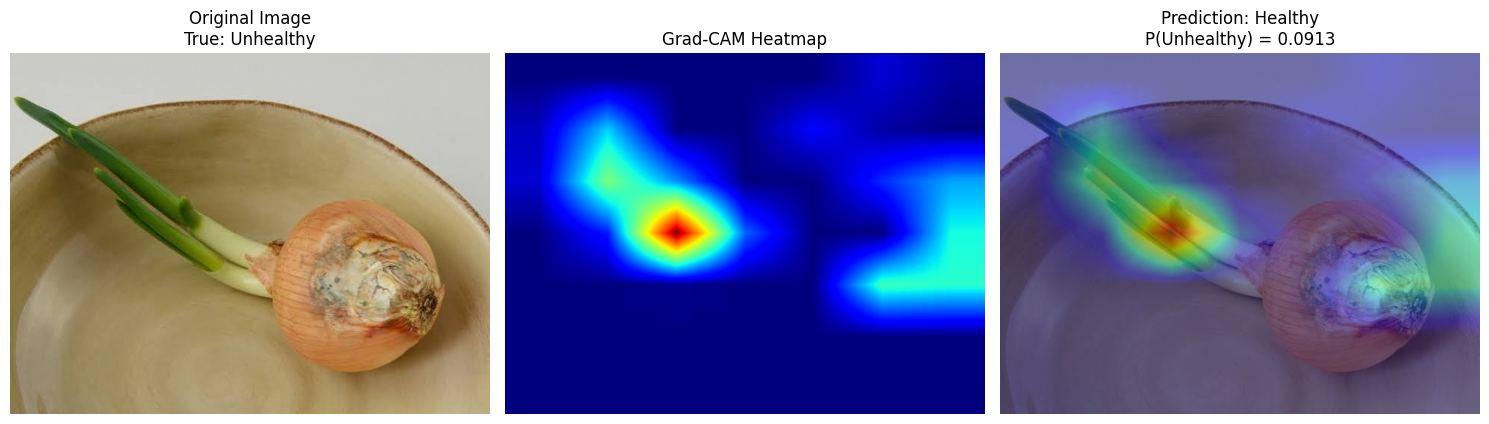

In [ ]:
# ============================================================
# 41. GENERATE GRAD-CAM FOR test_img9.jpg
# ============================================================
# Red/yellow regions indicate areas that had stronger influence
# on the model's unhealthy-class output.
#
# This helps us inspect whether the model focused on meaningful
# damage regions or on less relevant visual features.

# Use the final feature layer of MobileNetV3-Small
target_layer = mobilenet.features[-1]


gradcam = GradCAM(
    mobilenet,
    target_layer
)


# Generate heatmap
heatmap = gradcam.generate(
    input_tensor
)


# Remove hooks after Grad-CAM is finished
gradcam.remove_hooks()


# ------------------------------------------------------------
# RESIZE HEATMAP TO ORIGINAL IMAGE SIZE
# ------------------------------------------------------------

heatmap_image = Image.fromarray(
    np.uint8(heatmap * 255)
)

heatmap_image = heatmap_image.resize(
    original_image.size,
    Image.Resampling.BILINEAR
)

heatmap_resized = np.array(
    heatmap_image
) / 255.0


# ------------------------------------------------------------
# DISPLAY ORIGINAL IMAGE + HEATMAP + OVERLAY
# ------------------------------------------------------------

plt.figure(figsize=(15, 5))


# Original image
plt.subplot(1, 3, 1)

plt.imshow(
    original_image
)

plt.title(
    "Original Image\nTrue: Unhealthy"
)

plt.axis("off")


# Grad-CAM heatmap
plt.subplot(1, 3, 2)

plt.imshow(
    heatmap_resized,
    cmap="jet"
)

plt.title(
    "Grad-CAM Heatmap"
)

plt.axis("off")


# Grad-CAM overlay
plt.subplot(1, 3, 3)

plt.imshow(
    original_image
)

plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"P(Unhealthy) = {probability_unhealthy:.4f}"
)

plt.axis("off")


plt.tight_layout()
plt.show()

In [ ]:
### Grad-CAM Interpretation

# The image `test_img9.jpg` is an unhealthy onion, but the fine-tuned
# MobileNetV3-Small predicts it as healthy with a low unhealthy probability
# of approximately 0.091.

# The Grad-CAM visualization shows that the model focuses strongly on the
# stem/neck region instead of concentrating mainly on the visibly damaged
# bulb area.

# This suggests that the model may sometimes rely on secondary or shortcut
# visual features rather than the most relevant disease-related regions.
# This helps explain why the image was misclassified.

# Grad-CAM therefore provides useful qualitative evidence about the model's
# decision-making behavior, although it does not by itself prove causality.

In [ ]:
# ============================================================
# 42. FINAL RESULTS SUMMARY
# ============================================================

# Calculate ROC-AUC for external holdout experiments
external_auc = roc_auc_score(
    external_labels,
    external_probabilities
)

ft_external_auc = roc_auc_score(
    ft_external_labels,
    ft_external_probabilities
)

results = pd.DataFrame({

    "Model / Experiment": [
        "SimpleCNN",
        "ImprovedCNN",
        "MobileNetV3-Small",
        "MobileNetV3-Small",
        "Fine-Tuned MobileNet",
        "Fine-Tuned MobileNet",
        "Fine-Tuned MobileNet"
    ],

    "Evaluation Set": [
        "Original Test (300)",
        "Original Test (300)",
        "Original Test (300)",
        "External Holdout (12)",
        "External Holdout (12)",
        "Original Test (300)",
        "New Unseen Test (10)"
    ],

    "Accuracy (%)": [
        simplecnn_results["Accuracy (%)"],
        improvedcnn_results["Accuracy (%)"],
        mobilenet_results["Accuracy (%)"],
        external_accuracy * 100,
        ft_external_accuracy * 100,
        ft_original_accuracy * 100,
        new_test_accuracy * 100
    ],

    "Precision (%)": [
        simplecnn_results["Precision (%)"],
        improvedcnn_results["Precision (%)"],
        mobilenet_results["Precision (%)"],
        external_precision * 100,
        ft_external_precision * 100,
        ft_original_precision * 100,
        new_test_precision * 100
    ],

    "Recall (%)": [
        simplecnn_results["Recall (%)"],
        improvedcnn_results["Recall (%)"],
        mobilenet_results["Recall (%)"],
        external_recall * 100,
        ft_external_recall * 100,
        ft_original_recall * 100,
        new_test_recall * 100
    ],

    "F1-score (%)": [
        simplecnn_results["F1-score (%)"],
        improvedcnn_results["F1-score (%)"],
        mobilenet_results["F1-score (%)"],
        external_f1 * 100,
        ft_external_f1 * 100,
        ft_original_f1 * 100,
        new_test_f1 * 100
    ],

    "ROC-AUC (%)": [
        simplecnn_results["ROC-AUC (%)"],
        improvedcnn_results["ROC-AUC (%)"],
        mobilenet_results["ROC-AUC (%)"],
        external_auc * 100,
        ft_external_auc * 100,
        ft_original_auc * 100,
        new_test_roc_auc * 100
    ]
})

results = results.round(2)

results

,Model / Experiment,Evaluation Set,Accuracy (%),Precision (%),Recall (%),F1-score (%),ROC-AUC (%)
0,SimpleCNN,Original Test (300),83.00,80.37,87.33,83.71,92.66
1,ImprovedCNN,Original Test (300),84.33,81.60,88.67,84.98,91.87
2,MobileNetV3-Small,Original Test (300),96.33,94.27,98.67,96.42,99.82
3,MobileNetV3-Small,External Holdout (12),75.00,80.00,66.67,72.73,88.89
4,Fine-Tuned MobileNet,External Holdout (12),91.67,100.00,83.33,90.91,94.44
5,Fine-Tuned MobileNet,Original Test (300),95.33,92.50,98.67,95.48,99.72
6,Fine-Tuned MobileNet,New Unseen Test (10),90.00,100.00,80.00,88.89,96.00


In [ ]:
print("SimpleCNN Confusion Matrix:")
print(simplecnn_results["Confusion Matrix"])

print("\nImprovedCNN Confusion Matrix:")
print(improvedcnn_results["Confusion Matrix"])

print("\nMobileNetV3-Small Confusion Matrix:")
print(mobilenet_results["Confusion Matrix"])

print("\nOriginal MobileNet - External Holdout:")
print(external_cm)

print("\nFine-Tuned MobileNet - External Holdout:")
print(ft_external_cm)

print("\nFine-Tuned MobileNet - Original Test:")
print(ft_original_cm)

print("\nFine-Tuned MobileNet - New Unseen Test:")
print(new_test_cm)

SimpleCNN Confusion Matrix:
[[118  32]
 [ 19 131]]

ImprovedCNN Confusion Matrix:
[[120  30]
 [ 17 133]]

MobileNetV3-Small Confusion Matrix:
[[141   9]
 [  2 148]]

Original MobileNet - External Holdout:
[[5 1]
 [2 4]]

Fine-Tuned MobileNet - External Holdout:
[[6 0]
 [1 5]]

Fine-Tuned MobileNet - Original Test:
[[138  12]
 [  2 148]]

Fine-Tuned MobileNet - New Unseen Test:
[[5 0]
 [1 4]]
